#Q1

Obtain the daily historical data of 10 Nifty 50 stocks belonging to different sectors and the Nifty 50 index for the period 01/01/2019 to 31/12/2024. Perform the following:

In [ ]:
import yfinance as yf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize

tickers = ["RELIANCE.NS", "TCS.NS", "HDFCBANK.NS", "HINDUNILVR.NS", "SUNPHARMA.NS",
           "MARUTI.NS", "LT.NS", "TATASTEEL.NS", "BHARTIARTL.NS", "ULTRACEMCO.NS"]

data = yf.download(tickers, start="2019-01-01", end="2025-01-01")
prices = data['Close'][tickers].ffill().dropna()

nifty = yf.download("^NSEI", start="2019-01-01", end="2025-01-01")["Close"].squeeze()
nifty_returns = np.log(nifty / nifty.shift(1)).dropna()

Rf = 0.065   # risk free rate
TRADING_DAYS = 252

prices.head()

/tmp/ipykernel_751/3186757373.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start="2019-01-01", end="2025-01-01")
[*********************100%***********************]  10 of 10 completed
/tmp/ipykernel_751/3186757373.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  nifty = yf.download("^NSEI", start="2019-01-01", end="2025-01-01")["Close"].squeeze()
[*********************100%***********************]  1 of 1 completed


Ticker,RELIANCE.NS,TCS.NS,HDFCBANK.NS,HINDUNILVR.NS,SUNPHARMA.NS,MARUTI.NS,LT.NS,TATASTEEL.NS,BHARTIARTL.NS,ULTRACEMCO.NS
Date,,,,,,,,,,
2019-01-01,496.196350,1552.488159,496.185883,1591.314453,401.703064,6934.813965,1283.006348,41.323269,276.940063,3801.115967
2019-01-02,489.733917,1569.214233,491.658508,1576.736206,407.725647,6741.011230,1268.413696,39.552559,271.002533,3798.176758
2019-01-03,483.691895,1550.162720,487.800995,1580.093750,404.065796,6681.744629,1241.274658,38.559036,271.739349,3697.631104
2019-01-04,486.303436,1531.315430,489.106049,1574.173828,401.934753,6710.079102,1235.090454,39.071819,279.497131,3711.378662
2019-01-07,489.003571,1548.490112,489.845154,1577.045410,399.155182,6828.382812,1231.308838,38.899555,281.664093,3722.945068


(a) Calculate the daily logarithmic returns and estimate the annualized Expected return, Variance and Standard deviation. Construct the variance-covariance matrix and correlation matrix of the stock returns.

In [ ]:
returns = np.log(prices / prices.shift(1)).dropna()

annual_mean = (returns.mean())*TRADING_DAYS
annual_var = (returns.var())*TRADING_DAYS
annual_sd = (returns.std())*np.sqrt(TRADING_DAYS)
annual_covar = (returns.cov())*TRADING_DAYS
annual_corr = (returns.corr())

print("Annualized Mean Returns:")
print(annual_mean)
print("\nAnnualized Variance:")
print(annual_var)
print("\nAnnualized Standard Deviation:")
print(annual_sd)
print("\nAnnualized Covariance Matrix:")
display(annual_covar)
print("\nAnnualized Correlation Matrix:")
display(annual_corr)

Annualized Mean Returns:
Ticker
RELIANCE.NS      0.151081
TCS.NS           0.153024
HDFCBANK.NS      0.093719
HINDUNILVR.NS    0.059857
SUNPHARMA.NS     0.260224
MARUTI.NS        0.072812
LT.NS            0.172798
TATASTEEL.NS     0.197977
BHARTIARTL.NS    0.293791
ULTRACEMCO.NS    0.182888
dtype: float64

Annualized Variance:
Ticker
RELIANCE.NS      0.085348
TCS.NS           0.058607
HDFCBANK.NS      0.068695
HINDUNILVR.NS    0.052974
SUNPHARMA.NS     0.071631
MARUTI.NS        0.090959
LT.NS            0.080184
TATASTEEL.NS     0.142443
BHARTIARTL.NS    0.087514
ULTRACEMCO.NS    0.077990
dtype: float64

Annualized Standard Deviation:
Ticker
RELIANCE.NS      0.292143
TCS.NS           0.242089
HDFCBANK.NS      0.262098
HINDUNILVR.NS    0.230160
SUNPHARMA.NS     0.267639
MARUTI.NS        0.301594
LT.NS            0.283168
TATASTEEL.NS     0.377416
BHARTIARTL.NS    0.295828
ULTRACEMCO.NS    0.279267
dtype: float64

Annualized Covariance Matrix:


Ticker,RELIANCE.NS,TCS.NS,HDFCBANK.NS,HINDUNILVR.NS,SUNPHARMA.NS,MARUTI.NS,LT.NS,TATASTEEL.NS,BHARTIARTL.NS,ULTRACEMCO.NS
Ticker,,,,,,,,,,
RELIANCE.NS,0.085348,0.024634,0.032021,0.020554,0.023119,0.035848,0.032675,0.043127,0.026139,0.032855
TCS.NS,0.024634,0.058607,0.017789,0.016494,0.014756,0.020937,0.019452,0.028111,0.017262,0.021348
HDFCBANK.NS,0.032021,0.017789,0.068695,0.016077,0.015658,0.033314,0.037633,0.037025,0.025118,0.032482
HINDUNILVR.NS,0.020554,0.016494,0.016077,0.052974,0.013787,0.023809,0.016848,0.015040,0.014942,0.021268
SUNPHARMA.NS,0.023119,0.014756,0.015658,0.013787,0.071631,0.022385,0.022242,0.032022,0.021207,0.023304
MARUTI.NS,0.035848,0.020937,0.033314,0.023809,0.022385,0.090959,0.038794,0.042248,0.029156,0.039893
LT.NS,0.032675,0.019452,0.037633,0.016848,0.022242,0.038794,0.080184,0.048010,0.029133,0.040857
TATASTEEL.NS,0.043127,0.028111,0.037025,0.015040,0.032022,0.042248,0.048010,0.142443,0.035216,0.048159
BHARTIARTL.NS,0.026139,0.017262,0.025118,0.014942,0.021207,0.029156,0.029133,0.035216,0.087514,0.029261



Annualized Correlation Matrix:


Ticker,RELIANCE.NS,TCS.NS,HDFCBANK.NS,HINDUNILVR.NS,SUNPHARMA.NS,MARUTI.NS,LT.NS,TATASTEEL.NS,BHARTIARTL.NS,ULTRACEMCO.NS
Ticker,,,,,,,,,,
RELIANCE.NS,1.000000,0.348303,0.418197,0.305683,0.295678,0.406861,0.394985,0.391139,0.302451,0.402710
TCS.NS,0.348303,1.000000,0.280361,0.296024,0.227741,0.286754,0.283760,0.307670,0.241035,0.315770
HDFCBANK.NS,0.418197,0.280361,1.000000,0.266515,0.223219,0.421441,0.507064,0.374288,0.323952,0.443777
HINDUNILVR.NS,0.305683,0.296024,0.266515,1.000000,0.223823,0.342994,0.258503,0.173134,0.219453,0.330877
SUNPHARMA.NS,0.295678,0.227741,0.223219,0.223823,1.000000,0.277321,0.293488,0.317013,0.267845,0.311793
MARUTI.NS,0.406861,0.286754,0.421441,0.342994,0.277321,1.000000,0.454250,0.371164,0.326788,0.473643
LT.NS,0.394985,0.283760,0.507064,0.258503,0.293488,0.454250,1.000000,0.449233,0.347778,0.516656
TATASTEEL.NS,0.391139,0.307670,0.374288,0.173134,0.317013,0.371164,0.449233,1.000000,0.315415,0.456915
BHARTIARTL.NS,0.302451,0.241035,0.323952,0.219453,0.267845,0.326788,0.347778,0.315415,1.000000,0.354187


(b) For each stock, calculate the ratio:
- sharpie
- sortino
- treynor
- CV

Compare the stocks using these measures and explain how the assessment changes when total risk, downside risk and systematic risk are considered.

In [ ]:
daily_rf = Rf / TRADING_DAYS

downside = np.minimum(returns - daily_rf, 0)
downside_sd = np.sqrt((downside ** 2).mean())
annual_downside_sd = downside_sd * np.sqrt(TRADING_DAYS)

beta = returns.apply(
    lambda x: x.cov(nifty_returns) / nifty_returns.var()
)

sharpie = (annual_mean - Rf)/annual_sd
sortino = (annual_mean - Rf)/annual_downside_sd
treynor = (annual_mean - Rf)/beta
CV = annual_sd/annual_mean

print("\nSharpie: ", sharpie)
print("\nSortino: ", sortino)
print("\nTreynor: ", treynor)
print("\nCV: ", CV)


Sharpie:  Ticker
RELIANCE.NS      0.294652
TCS.NS           0.363603
HDFCBANK.NS      0.109575
HINDUNILVR.NS   -0.022344
SUNPHARMA.NS     0.729429
MARUTI.NS        0.025903
LT.NS            0.380687
TATASTEEL.NS     0.352336
BHARTIARTL.NS    0.773394
ULTRACEMCO.NS    0.422133
dtype: float64

Sortino:  Ticker
RELIANCE.NS      0.430818
TCS.NS           0.519110
HDFCBANK.NS      0.152891
HINDUNILVR.NS   -0.033462
SUNPHARMA.NS     1.085699
MARUTI.NS        0.036554
LT.NS            0.536322
TATASTEEL.NS     0.497887
BHARTIARTL.NS    1.178404
ULTRACEMCO.NS    0.609627
dtype: float64

Treynor:  Ticker
RELIANCE.NS      0.078829
TCS.NS           0.124288
HDFCBANK.NS      0.026688
HINDUNILVR.NS   -0.009065
SUNPHARMA.NS     0.315611
MARUTI.NS        0.007660
LT.NS            0.100373
TATASTEEL.NS     0.107059
BHARTIARTL.NS    0.286141
ULTRACEMCO.NS    0.118650
dtype: float64

CV:  Ticker
RELIANCE.NS      1.933689
TCS.NS           1.582029
HDFCBANK.NS      2.796628
HINDUNILVR.NS    3.845144
SUNP

(c) Using Nifty 50 as the market portfolio, estimate each stock's beta and alpha from:

Ri - Rf = alpha + beta(Rm - Rf) + epsilon_i

Calculate the CAPM expected return:

E(Ri) = Rf + beta [ E(Rm) - Rf ]

Compare the historical return with the CAPM-implied return.

In [ ]:
# alpha, beta, CAPM

# align it to fit reg line later
combined = pd.concat([returns, nifty_returns.rename("NIFTY")], axis=1).dropna()
returns = combined[tickers]
nifty_returns = combined["NIFTY"]

stock_excess = returns - daily_rf
market_excess = nifty_returns - daily_rf

alpha = {}
beta = {}
for stock in tickers:
    b, a = np.polyfit(market_excess, stock_excess[stock], 1)
    beta[stock] = b
    alpha[stock] = a
beta = pd.Series(beta)
alpha = pd.Series(alpha)

print("\nAlpha:\n", alpha)
print("\nBeta:\n", beta)

market_return = nifty_returns.mean()*TRADING_DAYS
capm_return = Rf + beta*(market_return - Rf)

print('\nCAPM Return:\n', capm_return)


Alpha:
 RELIANCE.NS      0.000050
TCS.NS           0.000149
HDFCBANK.NS     -0.000183
HINDUNILVR.NS   -0.000168
SUNPHARMA.NS     0.000590
MARUTI.NS       -0.000228
LT.NS            0.000134
TATASTEEL.NS     0.000207
BHARTIARTL.NS    0.000702
ULTRACEMCO.NS    0.000198
dtype: float64

Beta:
 RELIANCE.NS      1.091989
TCS.NS           0.708226
HDFCBANK.NS      1.076111
HINDUNILVR.NS    0.567316
SUNPHARMA.NS     0.618558
MARUTI.NS        1.019899
LT.NS            1.073975
TATASTEEL.NS     1.242099
BHARTIARTL.NS    0.799574
ULTRACEMCO.NS    0.993579
dtype: float64

CAPM Return:
 RELIANCE.NS      0.140143
TCS.NS           0.113735
HDFCBANK.NS      0.139050
HINDUNILVR.NS    0.104039
SUNPHARMA.NS     0.107565
MARUTI.NS        0.135182
LT.NS            0.138903
TATASTEEL.NS     0.150472
BHARTIARTL.NS    0.120021
ULTRACEMCO.NS    0.133371
dtype: float64


(d) Construct the Security Market Line (SML) and plot the individual stocks against their estimated beta. Calculate the deviation of each stock from the SML and analyze the relationship between beta, expected return and alpha.

Deviation:
 Ticker
RELIANCE.NS      0.010938
TCS.NS           0.039289
HDFCBANK.NS     -0.045331
HINDUNILVR.NS   -0.044181
SUNPHARMA.NS     0.152659
MARUTI.NS       -0.062370
LT.NS            0.033895
TATASTEEL.NS     0.047505
BHARTIARTL.NS    0.173770
ULTRACEMCO.NS    0.049517
dtype: float64


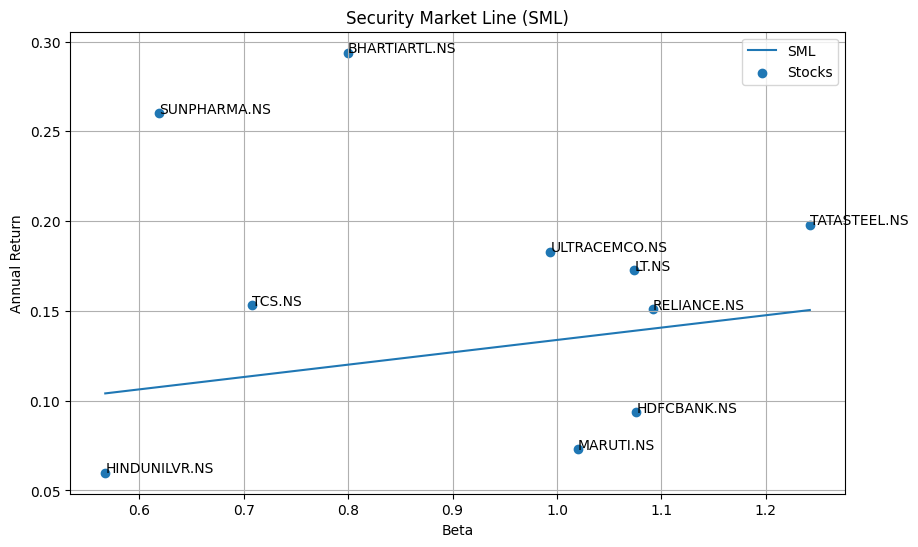

In [ ]:
# SML and deviation
deviation = annual_mean - capm_return
print('Deviation:\n', deviation)

beta_line = np.linspace(beta.min(), beta.max(), 100)
sml_line = Rf + beta_line*(market_return - Rf)

plt.figure(figsize=(10, 6))
# SML
plt.plot(beta_line, sml_line, label="SML")
# Individual stocks
plt.scatter(beta, annual_mean, label="Stocks")
# Add stock names
for stock in tickers:
    plt.annotate(stock,(beta[stock], annual_mean[stock]))
plt.xlabel("Beta")
plt.ylabel("Annual Return")
plt.title("Security Market Line (SML)")
plt.legend()
plt.grid(True)
plt.show()

(e) Construct an equal-weighted portfolio of the 10 stocks and calculate its Expected return, Standard deviation, Beta, Sharpe ratio, Treynor ratio and Jensen's alpha Compare the portfolio-level measures with the corresponding individual-stock measures.

In [ ]:
# Equal - weighted portfolio
n = len(tickers)
weights = np.ones(n)/n

portfolio_return = annual_mean @ weights

portfolio_expected_return = portfolio_return.mean() * TRADING_DAYS
portfolio_var = weights @ annual_covar @ weights
portfolio_sd = np.sqrt(portfolio_var)

portfolio_beta = weights @ beta
portfolio_sharpe = (portfolio_return - Rf) / portfolio_sd
portfolio_treynor = (portfolio_return - Rf) / portfolio_beta

portfolio_capm_return = Rf + portfolio_beta * (market_return - Rf)
portfolio_alpha = portfolio_return - portfolio_capm_return

print("Potfolio measures: ")
print("Expected Return: ", portfolio_expected_return)
print("Standard Deviation: ", portfolio_sd)
print("Beta: ", portfolio_beta)
print("Sharpe Ratio: ", portfolio_sharpe)
print("Treynor Ratio: ", portfolio_treynor)
print("Jensen's Alpha: ", portfolio_alpha)
print("CAPM return: ", portfolio_capm_return)

Potfolio measures: 
Expected Return:  41.2819405281443
Standard Deviation:  0.18111779258260782
Beta:  0.9191326070733112
Sharpe Ratio:  0.5455964480848141
Treynor Ratio:  0.10751139014933361
Jensen's Alpha:  0.03556911828379494
CAPM return:  0.12824810603423797


#Q2

Using the same 10 Nifty 50 stocks and the return period 01/01/2019 to 31/12/2024, formulate and solve a constrained Markowitz mean–variance portfolio optimization problem.

In [ ]:
import yfinance as yf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize

tickers = ["RELIANCE.NS", "TCS.NS", "HDFCBANK.NS", "HINDUNILVR.NS", "SUNPHARMA.NS",
           "MARUTI.NS", "LT.NS", "TATASTEEL.NS", "BHARTIARTL.NS", "ULTRACEMCO.NS"]

data = yf.download(tickers, start="2019-01-01", end="2025-01-01")
prices = data['Close'][tickers].ffill().dropna()
returns = np.log(prices / prices.shift(1)).dropna()

nifty = yf.download("^NSEI", start="2019-01-01", end="2025-01-01")["Close"].squeeze()
nifty_returns = np.log(nifty / nifty.shift(1)).dropna()

TRADING_DAYS = 252
Rf = 0.065

n = len(tickers)

/tmp/ipykernel_751/166993812.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start="2019-01-01", end="2025-01-01")
[*********************100%***********************]  10 of 10 completed
/tmp/ipykernel_751/166993812.py:14: FutureWarning: YF.download() has changed argument auto_adjust default to True
  nifty = yf.download("^NSEI", start="2019-01-01", end="2025-01-01")["Close"].squeeze()
[*********************100%***********************]  1 of 1 completed


(i) Estimate the expected return vector μ and covariance matrix Σ from the historical daily returns. Annualize the required quantities consistently.

In [ ]:
annual_mean = returns.mean() * TRADING_DAYS
annual_cov = returns.cov() * TRADING_DAYS

mu = annual_mean
sigma = annual_cov

print("Mu: ", mu)
print("\nSigma: ", sigma)

Mu:  Ticker
RELIANCE.NS      0.151081
TCS.NS           0.153024
HDFCBANK.NS      0.093719
HINDUNILVR.NS    0.059857
SUNPHARMA.NS     0.260224
MARUTI.NS        0.072812
LT.NS            0.172798
TATASTEEL.NS     0.197977
BHARTIARTL.NS    0.293791
ULTRACEMCO.NS    0.182888
dtype: float64

Sigma:  Ticker         RELIANCE.NS    TCS.NS  HDFCBANK.NS  HINDUNILVR.NS  \
Ticker                                                             
RELIANCE.NS       0.085348  0.024634     0.032021       0.020554   
TCS.NS            0.024634  0.058607     0.017789       0.016494   
HDFCBANK.NS       0.032021  0.017789     0.068695       0.016077   
HINDUNILVR.NS     0.020554  0.016494     0.016077       0.052974   
SUNPHARMA.NS      0.023119  0.014756     0.015658       0.013787   
MARUTI.NS         0.035848  0.020937     0.033314       0.023809   
LT.NS             0.032675  0.019452     0.037633       0.016848   
TATASTEEL.NS      0.043127  0.028111     0.037025       0.015040   
BHARTIARTL.NS     0.0261

(ii) Determine the Global Minimum Variance Portfolio (GMVP) by minimizing portfolio variance wTΣw subject to Σwi = 1 and 0 ≤ wi ≤ 1.

In [ ]:
# GMVP
def portfolio_variance(w):
    return w.T @ sigma @ w

constraints = {
    "type": "eq",
    "fun": lambda w: np.sum(w) - 1
}

bounds = [(0,1)]*n
initial_weights = np.ones(n)/n

gmvp = minimize(
    portfolio_variance,
    initial_weights,
    method='SLSQP',
    bounds=bounds,
    constraints=constraints
)

gmvp_weights = gmvp.x
print("GMVP weights:\n", gmvp_weights)

GMVP weights:
 [1.93809859e-02 2.23233257e-01 1.36397504e-01 2.78086528e-01
 1.78775355e-01 2.87862463e-03 4.61540060e-02 2.65629532e-18
 9.55216298e-02 1.95721102e-02]


(iii) Generate at least 30 feasible target returns between the minimum and maximum individual expected returns. For each target return μ0, minimize portfolio variance subject to Σwi = 1, wTμ = μ0 and 0 ≤ wi ≤ 1.

(iv) Calculate the portfolio expected return and standard deviation for every optimized target-return portfolio and plot the resulting efficient frontier.

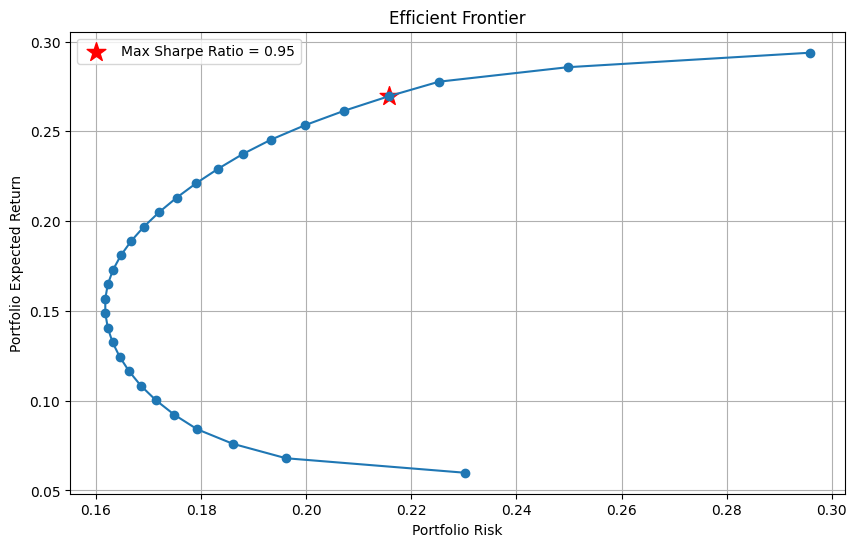

In [ ]:
# Efficient frontier point: GMVP with target return constraint and plotting

target_returns = np.linspace(mu.min(), mu.max(), 30)

frontier_returns = []
frontier_risks = []
frontier_weights = []
sharpe_ratios = []

bounds = [(0,1)]*n
initial_weights = np.ones(n)/n

for target in target_returns:
    constraints = [
        {
            "type": "eq",
            "fun": lambda w: np.sum(w) - 1,
        },
        {
            "type":"eq",
            "fun": lambda w, target=target: w @ mu - target,
        }
    ]

    res = minimize(
        portfolio_variance,
        initial_weights,
        method='SLSQP',
        bounds=bounds,
        constraints = constraints
    )

    if res.success:
        w = res.x

        portfolio_return = w.T @ mu
        portfolio_variance_value = w.T @ sigma @ w
        portfolio_sd = np.sqrt(portfolio_variance_value)
        sharpe = (portfolio_return - Rf) / portfolio_sd  # Sharpe ratio

        frontier_returns.append(portfolio_return)
        frontier_risks.append(portfolio_sd)
        frontier_weights.append(w)
        sharpe_ratios.append(sharpe)



# Find portfolio with maximum Sharpe ratio
max_sharpe_idx = np.argmax(sharpe_ratios)
max_sharpe_return = frontier_returns[max_sharpe_idx]
max_sharpe_risk = frontier_risks[max_sharpe_idx]
max_sharpe_ratio = sharpe_ratios[max_sharpe_idx]
max_sharpe_weights = frontier_weights[max_sharpe_idx]


# plotting
plt.figure(figsize=(10, 6))
plt.plot(frontier_risks,frontier_returns,marker='o')
plt.scatter(max_sharpe_risk, max_sharpe_return, color="red", marker="*", s=200, label=f"Max Sharpe Ratio = {max_sharpe_ratio:.2f}")
plt.xlabel("Portfolio Risk")
plt.ylabel("Portfolio Expected Return")
plt.title("Efficient Frontier")
plt.grid(True)
plt.legend()
plt.show()

(v) Identify the GMVP, maximum-return portfolio and the tangency (maximum-Sharpe) portfolio from the efficient frontier.

In [ ]:
# Identify the GMVP, maximum-return portfolio and the tangency (maximum-Sharpe)
# portfolio from the efficient frontier.

gmvp_return = gmvp_weights.T @ mu
gmvp_variance = gmvp_weights.T @ sigma @ gmvp_weights
gmvp_sd = np.sqrt(gmvp_variance)

max_return_idx = np.argmax(frontier_returns)
max_return = frontier_returns[max_return_idx]
max_return_sd = frontier_risks[max_return_idx]
max_return_weights = frontier_weights[max_return_idx]

frontier_returns = np.array(frontier_returns)  # mean
frontier_risks = np.array(frontier_risks)      # sd
frontier_weights = np.array(frontier_weights)

frontier_sharpe = (frontier_returns - Rf) / frontier_risks
tangency_idx = np.argmax(frontier_sharpe)
tangency_return = frontier_returns[tangency_idx]
tangency_sd = frontier_risks[tangency_idx]
tangency_sharpe = frontier_sharpe[tangency_idx]
tangency_weights = frontier_weights[tangency_idx]

print("GMVP")
print("Return:", gmvp_return)
print("Risk:", gmvp_sd)
print("Weights:\n", gmvp_weights)

print("\nMaximum Return Portfolio")
print("Return:", max_return)
print("Risk:", max_return_sd)
print("Weights:\n", max_return_weights)

print("\nTangency Portfolio")
print("Return:", tangency_return)
print("Risk:", tangency_sd)
print("Sharpe:", tangency_sharpe)
print("Weights:\n", tangency_weights)

GMVP
Return: 0.1528662736006742
Risk: 0.16171197468953027
Weights:
 [1.93809859e-02 2.23233257e-01 1.36397504e-01 2.78086528e-01
 1.78775355e-01 2.87862463e-03 4.61540060e-02 2.65629532e-18
 9.55216298e-02 1.95721102e-02]

Maximum Return Portfolio
Return: 0.29379117446736236
Risk: 0.2958275532496041
Weights:
 [0.00000000e+00 0.00000000e+00 2.26207941e-15 5.55111512e-17
 3.73747691e-08 0.00000000e+00 1.38777878e-16 0.00000000e+00
 9.99999963e-01 0.00000000e+00]

Tangency Portfolio
Return: 0.26959112685247766
Risk: 0.2157549305266736
Sharpe: 0.948257017130759
Weights:
 [2.81892565e-18 6.07522926e-02 0.00000000e+00 7.42678488e-18
 4.66171203e-01 0.00000000e+00 1.51788304e-18 2.38524478e-18
 4.73076504e-01 1.99493200e-17]


(vi) Obtain the maximum-Sharpe portfolio directly by maximizing (wTμ − Rf) / √(wTΣw), subject to the same long-only and full-investment constraints. Compare it with the tangency portfolio obtained from the frontier.

In [ ]:
# maximise sharpe (minimize negative sharpe)

def negative_sharpe(w):
    portfolio_return = w @ mu
    portfolio_sd = np.sqrt(w.T @ sigma @ w)
    sharpe = (portfolio_return - Rf) / portfolio_sd
    return -sharpe

constraints = {
    "type": "eq",
    "fun": lambda w: np.sum(w) - 1
}

bounds = [(0, 1)] * n
initial_weights = np.ones(n) / n

max_sharpe_result = minimize(
    negative_sharpe,
    initial_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints
)

max_sharpe_weights = max_sharpe_result.x
print("Maximum sharpe weights:\n", max_sharpe_weights)

Maximum sharpe weights:
 [5.56866823e-17 8.40365832e-02 8.80372164e-17 7.09610322e-17
 4.53826587e-01 0.00000000e+00 0.00000000e+00 0.00000000e+00
 4.54225262e-01 7.91156862e-03]


(vii) Compare the equal-weighted portfolio, GMVP, maximum-Sharpe portfolio and maximum-return portfolio in terms of asset weights, expected return, risk, Sharpe ratio, beta and Jensen's alpha.

In [ ]:
# compare
asset_betas = returns.apply(lambda x: x.cov(nifty_returns) / nifty_returns.var())

def portfolio_metrics(w):
    portfolio_return = w.T @ mu
    portfolio_variance = w.T @ sigma @ w
    portfolio_sd = np.sqrt(portfolio_variance)
    portfolio_sharpe = (portfolio_return - Rf) / portfolio_sd
    portfolio_beta = w.T @ asset_betas
    portfolio_alpha = portfolio_return - (Rf + portfolio_beta * (market_return - Rf))
    return (
        portfolio_return,
        portfolio_sd,
        portfolio_sharpe,
        portfolio_beta,
        portfolio_alpha
    )

results = []

equal_weights = np.ones(n) / n
portfolios = {
    "Equal Weights": equal_weights,
    "GMVP": gmvp_weights,
    "Max Sharpe": max_sharpe_weights,
    "Max Return": max_return_weights
}

for name, w in portfolios.items():
    ret, sd, sharpe, beta, alpha = portfolio_metrics(w)
    results.append([name, ret, sd, sharpe, beta, alpha])

comparison_q2 = pd.DataFrame(
    results,
    columns=[
        "Portfolio",
        "Expected Return",
        "Risk (SD)",
        "Sharpe",
        "Portfolio Beta",
        "Jensen Alpha"
    ]
)
display(comparison_q2)

,Portfolio,Expected Return,Risk (SD),Sharpe,Portfolio Beta,Jensen Alpha
0,Equal Weights,0.163817,0.181118,0.545596,0.919133,0.035569
1,GMVP,0.152866,0.161712,0.543350,0.742715,0.036758
2,Max Sharpe,0.265850,0.211708,0.948716,0.711282,0.151905
3,Max Return,0.293791,0.295828,0.773394,0.799574,0.173770


(viii) Interpret how diversification and covariance among assets influence the shape and location of the efficient frontier.

#Q3

Using the same 10-stock universe and the estimated expected-return vector and covariance matrix from Question 2, investigate the effect of stochastic target returns on constrained portfolio optimization.

In [ ]:
import yfinance as yf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize

tickers = ["RELIANCE.NS", "TCS.NS", "HDFCBANK.NS", "HINDUNILVR.NS", "SUNPHARMA.NS",
           "MARUTI.NS", "LT.NS", "TATASTEEL.NS", "BHARTIARTL.NS", "ULTRACEMCO.NS"]

data = yf.download(tickers, start="2019-01-01", end="2025-01-01")
prices = data['Close'][tickers].ffill().dropna()
returns = np.log(prices / prices.shift(1)).dropna()

nifty = yf.download("^NSEI", start="2019-01-01", end="2025-01-01")["Close"].squeeze()
nifty_returns = np.log(nifty / nifty.shift(1)).dropna()

TRADING_DAYS = 252
Rf = 0.065

n = len(tickers)

annual_mean = returns.mean() * TRADING_DAYS
annual_cov = returns.cov() * TRADING_DAYS

mu = annual_mean
sigma = annual_cov

/tmp/ipykernel_751/3777095707.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start="2019-01-01", end="2025-01-01")
[*********************100%***********************]  10 of 10 completed
/tmp/ipykernel_751/3777095707.py:14: FutureWarning: YF.download() has changed argument auto_adjust default to True
  nifty = yf.download("^NSEI", start="2019-01-01", end="2025-01-01")["Close"].squeeze()
[*********************100%***********************]  1 of 1 completed


(i) Generate 1000 target returns using each of the following distributions: Uniform over the feasible expected-return range; Normal with mean (μmin + μmax)/2 and standard deviation (μmax − μmin)/6; and an Exponential distribution transformed/scaled to the feasible target-return range.

In [ ]:
import numpy as np

np.random.seed(42)
n_targets = 1000

mu_min = np.min(mu)
mu_max = np.max(mu)

# Uniform distribution
uniform_targets = np.random.uniform(mu_min, mu_max, n_targets)


# Normal distribution
normal_mean = (mu_min + mu_max) / 2
normal_sd = (mu_max - mu_min) / 6

normal_targets = np.random.normal(normal_mean, normal_sd, n_targets)

# normal_targets = []
# while len(normal_targets) < 1000:
#     values = np.random.normal(normal_mean, normal_sd, 2000)
#     values = values[(values >= mu_min) & (values <= mu_max)]
#     normal_targets.extend(values)
# normal_targets = np.array(normal_targets[:1000])

# Exponential distribution
exp_raw = np.random.exponential(scale=1.0, size=n_targets)
exp_scaled = (exp_raw / exp_raw.max())

exponential_targets = (mu_min + exp_scaled * (mu_max - mu_min))

(ii) For every generated target return, solve the Markowitz minimum-variance problem subject to Σwi = 1, wTμ = μ0 and 0 ≤ wi ≤ 1. Record the target return, actual portfolio return, variance, standard deviation, Sharpe ratio, portfolio weights and optimization status.

In [ ]:
def portfolio_variance(w):
  return w.T @ sigma @ w


def optimize_target(target):
  constraints = [
    {
        "type": "eq",
        "fun": lambda w: np.sum(w) - 1
    },
    {
        "type": "eq",
        "fun": lambda w, target=target: w.T @ mu - target
    }
  ]

  result = minimize(
    portfolio_variance,
    initial_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints
  )

  if result.success:
    w = result.x
    portfolio_return = w.T @ mu
    portfolio_variance_value = w.T @ sigma @ w
    portfolio_sd = np.sqrt(portfolio_variance_value)
    sharpe = (portfolio_return - Rf) / portfolio_sd
    return {
        "target": target,
        "return": portfolio_return,
        "variance": portfolio_variance_value,
        "risk": portfolio_sd,
        "sharpe": sharpe,
        "weights": w,
        "status": True
    }

  else:
    return {
        "target": target,
        "return": np.nan,
        "variance": np.nan,
        "risk": np.nan,
        "sharpe": np.nan,
        "weights": np.full(n, np.nan),
        "status": False
    }

In [ ]:
uniform_results = []
for target in uniform_targets:
    uniform_results.append(optimize_target(target))

normal_results = []
for target in normal_targets:
    normal_results.append(optimize_target(target))

exponential_results = []
for target in exponential_targets:
    exponential_results.append(optimize_target(target))


def results_to_dataframe(results):
    rows = []
    for r in results:
        row = {
            "Target": r["target"],
            "Return": r["return"],
            "Variance": r["variance"],
            "Risk": r["risk"],
            "Sharpe": r["sharpe"],
            "Status": r["status"]
        }
        for i, stock in enumerate(tickers):
            row[stock] = r["weights"][i]
        rows.append(row)
    return pd.DataFrame(rows)

uniform_df = results_to_dataframe(uniform_results)
normal_df = results_to_dataframe(normal_results)
exponential_df = results_to_dataframe(exponential_results)

display(uniform_df)
display(normal_df)
display(exponential_df)

,Target,Return,Variance,Risk,Sharpe,Status,RELIANCE.NS,TCS.NS,HDFCBANK.NS,HINDUNILVR.NS,SUNPHARMA.NS,MARUTI.NS,LT.NS,TATASTEEL.NS,BHARTIARTL.NS,ULTRACEMCO.NS
0,0.147475,0.147475,0.026184,0.161815,0.509688,True,1.865350e-02,2.214015e-01,1.458732e-01,2.919692e-01,0.168974,0.011606,4.300270e-02,1.246832e-18,8.443727e-02,1.408290e-02
1,0.282262,0.282262,0.055735,0.236084,0.920274,True,0.000000e+00,3.608225e-16,0.000000e+00,4.163336e-16,0.343476,0.000000,2.775558e-17,5.551115e-17,6.565238e-01,0.000000e+00
2,0.231095,0.231095,0.033968,0.184305,0.901200,True,3.851481e-03,2.219709e-01,2.324258e-18,2.504331e-02,0.342219,0.000000,5.522428e-02,2.764716e-18,2.897247e-01,6.196630e-02
3,0.199904,0.199904,0.028948,0.170141,0.792894,True,1.363665e-02,2.222069e-01,3.953150e-02,1.338336e-01,0.273840,0.000000,5.753826e-02,0.000000e+00,2.117073e-01,4.770600e-02
4,0.096355,0.096355,0.029928,0.172996,0.181249,True,4.067591e-03,2.030819e-01,2.283127e-01,4.305914e-01,0.041300,0.092646,0.000000e+00,8.820893e-19,3.225932e-20,1.875381e-18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0.081282,0.081282,0.032860,0.181273,0.089818,True,5.498892e-18,1.269874e-01,2.349637e-01,5.117027e-01,0.000000,0.126346,0.000000e+00,0.000000e+00,3.623356e-18,0.000000e+00
996,0.274448,0.274448,0.048994,0.221345,0.946251,True,2.260342e-17,2.302083e-02,0.000000e+00,0.000000e+00,0.479709,0.000000,9.953890e-18,1.098440e-18,4.972698e-01,1.411858e-17
997,0.091864,0.091864,0.030640,0.175043,0.153470,True,9.335722e-04,1.974965e-01,2.342046e-01,4.450612e-01,0.021376,0.100928,1.738567e-18,0.000000e+00,1.400322e-18,0.000000e+00
998,0.282150,0.282150,0.055563,0.235717,0.921232,True,0.000000e+00,0.000000e+00,7.494005e-16,0.000000e+00,0.346800,0.000000,0.000000e+00,0.000000e+00,6.531999e-01,1.110223e-16


,Target,Return,Variance,Risk,Sharpe,Status,RELIANCE.NS,TCS.NS,HDFCBANK.NS,HINDUNILVR.NS,SUNPHARMA.NS,MARUTI.NS,LT.NS,TATASTEEL.NS,BHARTIARTL.NS,ULTRACEMCO.NS
0,0.183753,0.183753,0.027348,0.165373,0.718088,True,0.015131,0.222592,0.072866,0.185303,0.242152,1.699148e-18,0.052576,0.000000e+00,0.172150,3.722963e-02
1,0.124761,0.124761,0.027041,0.164441,0.363417,True,0.015277,0.219851,0.181368,0.348249,0.126639,4.623147e-02,0.030317,1.114695e-18,0.031945,1.231549e-04
2,0.191648,0.191648,0.028047,0.167471,0.756237,True,0.014716,0.221898,0.056849,0.159644,0.257168,0.000000e+00,0.055495,4.607859e-18,0.191486,4.274349e-02
3,0.200630,0.200630,0.029036,0.170398,0.795960,True,0.013544,0.222237,0.038007,0.131561,0.275306,0.000000e+00,0.057717,0.000000e+00,0.213486,4.814270e-02
4,0.198650,0.198650,0.028800,0.169705,0.787543,True,0.013798,0.222156,0.042163,0.137756,0.271309,0.000000e+00,0.057229,0.000000e+00,0.208637,4.695244e-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0.125358,0.125358,0.027003,0.164326,0.367307,True,0.015505,0.219652,0.180623,0.346458,0.127647,4.557870e-02,0.031063,0.000000e+00,0.033475,1.509667e-20
996,0.152972,0.152972,0.026150,0.161711,0.544008,True,0.019259,0.221866,0.137051,0.278534,0.179148,2.941656e-03,0.045599,0.000000e+00,0.096845,1.875774e-02
997,0.175380,0.175380,0.026782,0.163652,0.674483,True,0.016950,0.221575,0.090999,0.210296,0.224341,5.461668e-18,0.051486,0.000000e+00,0.151532,3.282111e-02
998,0.160086,0.160086,0.026213,0.161903,0.587304,True,0.021107,0.220270,0.122593,0.256710,0.191946,0.000000e+00,0.048211,1.192622e-18,0.113653,2.550843e-02


,Target,Return,Variance,Risk,Sharpe,Status,RELIANCE.NS,TCS.NS,HDFCBANK.NS,HINDUNILVR.NS,SUNPHARMA.NS,MARUTI.NS,LT.NS,TATASTEEL.NS,BHARTIARTL.NS,ULTRACEMCO.NS
0,0.195702,0.195702,0.028467,0.168723,0.774657,True,1.418101e-02,2.220415e-01,0.048346,0.146973,2.653586e-01,2.141299e-18,5.649978e-02,1.788934e-18,2.014186e-01,4.518118e-02
1,0.075220,0.075220,0.034896,0.186803,0.054711,True,1.810371e-17,5.921029e-02,0.236233,0.561979,1.186248e-18,1.425778e-01,5.028927e-18,3.955533e-18,0.000000e+00,0.000000e+00
2,0.084967,0.084967,0.031923,0.178670,0.111756,True,0.000000e+00,1.682140e-01,0.234230,0.481255,0.000000e+00,1.163003e-01,0.000000e+00,1.518081e-18,9.299362e-19,2.691924e-18
3,0.068189,0.068189,0.038269,0.195625,0.016301,True,8.071051e-18,0.000000e+00,0.183629,0.653227,0.000000e+00,1.631439e-01,0.000000e+00,0.000000e+00,2.896360e-17,0.000000e+00
4,0.095874,0.095874,0.030000,0.173206,0.178253,True,3.576302e-03,2.026996e-01,0.228812,0.432417,3.917312e-02,9.332175e-02,0.000000e+00,1.966397e-18,0.000000e+00,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0.067593,0.067593,0.038750,0.196851,0.013171,True,0.000000e+00,3.246491e-17,0.164915,0.669046,1.122552e-17,1.660395e-01,2.252058e-17,0.000000e+00,0.000000e+00,0.000000e+00
996,0.133557,0.133557,0.026571,0.163005,0.420578,True,1.709027e-02,2.202562e-01,0.168222,0.326017,1.432203e-01,3.352583e-02,3.641078e-02,3.198396e-18,5.303437e-02,2.223703e-03
997,0.141610,0.141610,0.026294,0.162155,0.472448,True,1.800255e-02,2.209127e-01,0.155290,0.306304,1.581161e-01,2.085118e-02,4.023023e-02,0.000000e+00,7.120139e-02,9.091750e-03
998,0.083825,0.083825,0.032189,0.179412,0.104929,True,0.000000e+00,1.554125e-01,0.234536,0.490640,6.170216e-19,1.194120e-01,2.560265e-18,1.334419e-18,0.000000e+00,7.075831e-18


(iii) Construct and compare the portfolio risk–return frontiers generated from the three target-return distributions.

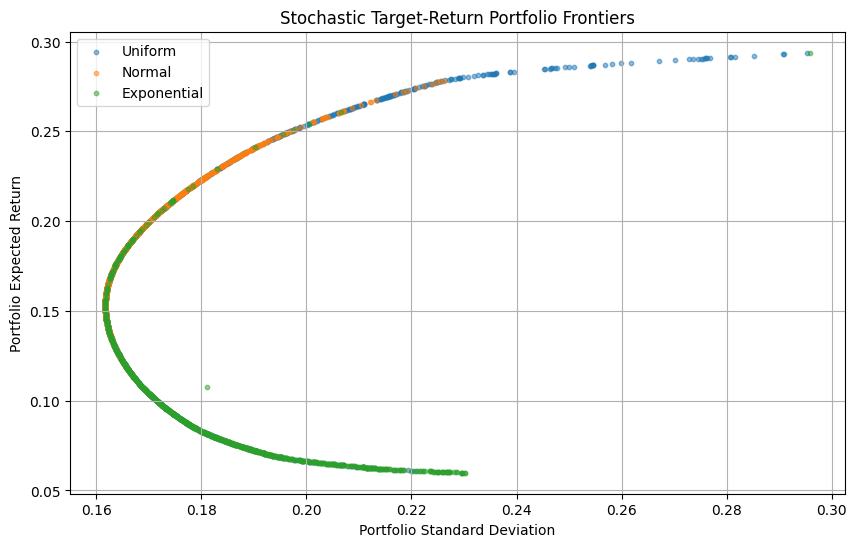

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(uniform_df["Risk"], uniform_df["Return"], s=10, alpha=0.5, label="Uniform")
plt.scatter(normal_df["Risk"], normal_df["Return"], s=10, alpha=0.5, label="Normal")
plt.scatter(exponential_df["Risk"], exponential_df["Return"], s=10, alpha=0.5, label="Exponential")
plt.xlabel("Portfolio Standard Deviation")
plt.ylabel("Portfolio Expected Return")
plt.title("Stochastic Target-Return Portfolio Frontiers")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Therefore, the three distributions should produce points along essentially the **same underlying feasible efficient frontier**,
# but the **density of points** will differ.

# * Uniform → points spread across the range
# * Normal → more points around the middle
# * Exponential → more points toward the lower-return region

(iv) For each distribution, calculate summary statistics such as mean, median, standard deviation, minimum and maximum of portfolio return, portfolio risk and Sharpe ratio.

In [ ]:
def summary_statistics(df):
  return pd.DataFrame(
    {
    "Mean": [
      df["Return"].mean(),
      df["Risk"].mean(),
      df["Sharpe"].mean()
    ],
    "Median": [
      df["Return"].median(),
      df["Risk"].median(),
      df["Sharpe"].median()
    ],
    "Std": [
      df["Return"].std(),
      df["Risk"].std(),
      df["Sharpe"].std()
    ],
    "Minimum": [
      df["Return"].min(),
      df["Risk"].min(),
      df["Sharpe"].min()
    ],
    "Maximum": [
      df["Return"].max(),
      df["Risk"].max(),
      df["Sharpe"].max()
    ]
  }, index=["Return", "Risk", "Sharpe"])

In [ ]:
print("UNIFORM")
display(summary_statistics(uniform_df))

print("\nNORMAL")
display(summary_statistics(normal_df))

print("\nEXPONENTIAL")
display(summary_statistics(exponential_df))

UNIFORM


,Mean,Median,Std,Minimum,Maximum
Return,0.174545,0.176077,0.068341,0.060941,0.293725
Risk,0.183386,0.174125,0.024836,0.161711,0.295387
Sharpe,0.583473,0.678233,0.320271,-0.018380,0.948694



NORMAL


,Mean,Median,Std,Minimum,Maximum
Return,0.180559,0.180032,0.038387,0.062924,0.278261
Risk,0.170192,0.165655,0.011187,0.161711,0.226154
Sharpe,0.672395,0.699104,0.190050,-0.009854,0.948705



EXPONENTIAL


,Mean,Median,Std,Minimum,Maximum
Return,0.096833,0.085429,0.036047,0.059858,0.293791
Risk,0.182651,0.178697,0.017314,0.161711,0.295828
Sharpe,0.187511,0.114520,0.211602,-0.022342,0.947835


(v) Identify the GMVP and maximum-Sharpe portfolio within the feasible optimized portfolios generated under each distribution and compare their characteristics.

In [ ]:
uniform_gmvp = uniform_df.loc[uniform_df["Risk"].idxmin()]
normal_gmvp = normal_df.loc[normal_df["Risk"].idxmin()]
exponential_gmvp = exponential_df.loc[exponential_df["Risk"].idxmin()]

uniform_max_sharpe = uniform_df.loc[uniform_df["Sharpe"].idxmax()]
normal_max_sharpe = normal_df.loc[normal_df["Sharpe"].idxmax()]
exponential_max_sharpe = exponential_df.loc[exponential_df["Sharpe"].idxmax()]

comparison_gmvp = pd.DataFrame({
    "Uniform GMVP": uniform_gmvp[["Target", "Return", "Risk", "Sharpe"]],
    "Normal GMVP": normal_gmvp[["Target", "Return", "Risk", "Sharpe"]],
    "Exponential GMVP": exponential_gmvp[["Target", "Return", "Risk", "Sharpe"]]
})

comparison_max_sharpe = pd.DataFrame({
    "Uniform": uniform_max_sharpe[["Target", "Return", "Risk", "Sharpe"]],
    "Normal": normal_max_sharpe[["Target", "Return", "Risk", "Sharpe"]],
    "Exponential": exponential_max_sharpe[["Target", "Return", "Risk", "Sharpe"]]
})

print("Comparison of GMVP")
display(comparison_gmvp)
print("\nComparison of Max sharpe")
display(comparison_max_sharpe)

Comparison of GMVP


,Uniform GMVP,Normal GMVP,Exponential GMVP
Target,0.152929,0.152972,0.153187
Return,0.152929,0.152972,0.153187
Risk,0.161711,0.161711,0.161711
Sharpe,0.543744,0.544008,0.54534



Comparison of Max sharpe


,Uniform,Normal,Exponential
Target,0.265128,0.266146,0.260736
Return,0.265128,0.266146,0.260736
Risk,0.210951,0.212021,0.206509
Sharpe,0.948694,0.948705,0.947835


(vi) Apply suitable statistical tests to examine whether the distributions produce statistically different portfolio risk and return characteristics. Clearly state the null and alternative hypotheses and justify the choice of test.

In [ ]:
from scipy.stats import f_oneway, kruskal

# Keep only finite Return and Risk values
uniform_valid = uniform_df[
    np.isfinite(uniform_df["Return"]) &
    np.isfinite(uniform_df["Risk"])
]

normal_valid = normal_df[
    np.isfinite(normal_df["Return"]) &
    np.isfinite(normal_df["Risk"])
]

exponential_valid = exponential_df[
    np.isfinite(exponential_df["Return"]) &
    np.isfinite(exponential_df["Risk"])
]


# ANOVA test
anova_return = f_oneway(
    uniform_valid["Return"],
    normal_valid["Return"],
    exponential_valid["Return"]
)

anova_risk = f_oneway(
    uniform_valid["Risk"],
    normal_valid["Risk"],
    exponential_valid["Risk"]
)

print("ANOVA - Return")
print("F statistic:", anova_return.statistic)
print("p-value:", anova_return.pvalue)

print("\nANOVA - Risk")
print("F statistic:", anova_risk.statistic)
print("p-value:", anova_risk.pvalue)


# Kruskal-Wallis test
kw_return = kruskal(
    uniform_valid["Return"],
    normal_valid["Return"],
    exponential_valid["Return"]
)

kw_risk = kruskal(
    uniform_valid["Risk"],
    normal_valid["Risk"],
    exponential_valid["Risk"]
)

print("\nKruskal-Wallis - Return")
print("Statistic:", kw_return.statistic)
print("p-value:", kw_return.pvalue)

print("\nKruskal-Wallis - Risk")
print("Statistic:", kw_risk.statistic)
print("p-value:", kw_risk.pvalue)

ANOVA - Return
F statistic: 878.698991793305
p-value: 5.09767169951413e-301

ANOVA - Risk
F statistic: 158.17062493021646
p-value: 4.980700927939649e-66

Kruskal-Wallis - Return
Statistic: 1185.2208504795017
p-value: 4.29103839047661e-258

Kruskal-Wallis - Risk
Statistic: 390.82072135097224
p-value: 1.362569463999697e-85


(vii) Perform sensitivity analysis by varying selected parameters such as the risk-free rate, target return, number of assets and portfolio-weight bounds. Examine the resulting changes in portfolio risk, return and asset weights.

In [ ]:
rf_values = [0.04, 0.065, 0.08]
rf_sensitivity = []

for rf in rf_values:
    sharpe = (uniform_df["Return"] - rf) / uniform_df["Risk"]
    rf_sensitivity.append({
        "Risk-Free Rate": rf,
        "Mean Sharpe": sharpe.mean(),
        "Maximum Sharpe": sharpe.max()
    })

rf_sensitivity = pd.DataFrame(rf_sensitivity)
rf_sensitivity

# Changing Rf does not change the Markowitz minimum-variance solution itself because the basic variance minimization doesn't use Rf.
# But it does change Sharpe ratios and therefore changes the direct maximum-Sharpe portfolio.

,Risk-Free Rate,Mean Sharpe,Maximum Sharpe
0,0.040,0.721904,1.069183
1,0.065,0.583473,0.948694
2,0.080,0.500414,0.878821


In [ ]:
selected_targets = [mu_min, (mu_min + mu_max) / 2, mu_max]
target_sensitivity = []

for target in selected_targets:
    result = optimize_target(target)
    if result["status"]:
        target_sensitivity.append({
            "Target": target,
            "Return": result["return"],
            "Risk": result["risk"]
        })

target_sensitivity = pd.DataFrame(target_sensitivity)
target_sensitivity

# As the required target return increases, the optimizer generally has to accept higher portfolio risk.
# This demonstrates the fundamental risk-return trade-off.

,Target,Return,Risk
0,0.059857,0.059857,0.230160
1,0.176824,0.176824,0.163911
2,0.293791,0.293791,0.295828


In [ ]:
asset_counts = [5, 7, 10]
asset_sensitivity = []

for k in asset_counts:
    mu_k = mu.iloc[:k]
    sigma_k = sigma.iloc[:k, :k]

    w0 = np.ones(k) / k
    bounds_k = [(0, 1)] * k

    constraints_k = {
        "type": "eq",
        "fun": lambda w: np.sum(w) - 1
    }

    result = minimize(
        lambda w: w.T @ sigma_k @ w,
        w0,
        method="SLSQP",
        bounds=bounds_k,
        constraints=constraints_k
    )

    w = result.x
    ret = w.T @ mu_k
    risk = np.sqrt(w.T @ sigma_k @ w)

    asset_sensitivity.append({
        "Number of Assets": k,
        "Return": ret,
        "Risk": risk
    })

asset_sensitivity = pd.DataFrame(asset_sensitivity)
asset_sensitivity

# Increasing the number of available assets can provide more diversification opportunities,
# although the exact effect depends on their expected returns and covariance structure.

,Number of Assets,Return,Risk
0,5,0.136123,0.164737
1,7,0.137744,0.163860
2,10,0.152866,0.161712


In [ ]:
upper_bounds = [0.20, 0.30, 1.00]
bound_sensitivity = []

for upper in upper_bounds:
    bounds_test = [(0, upper)] * n

    result = minimize(
        portfolio_variance,
        initial_weights,
        method="SLSQP",
        bounds=bounds_test,
        constraints=constraints
    )

    w = result.x
    ret = w.T @ mu
    risk = np.sqrt(w.T @ sigma @ w)

    bound_sensitivity.append({
        "Upper Weight Bound": upper,
        "Return": ret,
        "Risk": risk
    })

bound_sensitivity = pd.DataFrame(bound_sensitivity)
bound_sensitivity

# A tighter weight bound prevents the optimizer from putting too much money into a single stock.
# Therefore, the portfolio weights can become more diversified, but the optimizer has less freedom.

,Upper Weight Bound,Return,Risk
0,0.2,0.163128,0.162939
1,0.3,0.152866,0.161712
2,1.0,0.152866,0.161712


(viii) Measure portfolio-weight stability across repeated optimization runs and target-return distributions. Identify assets whose portfolio weights are relatively stable or highly sensitive to the optimization setting.

In [ ]:
uniform_weight_std = uniform_df[tickers].std()
normal_weight_std = normal_df[tickers].std()
exponential_weight_std = exponential_df[tickers].std()

weight_stability = pd.DataFrame({
    "Uniform": uniform_weight_std,
    "Normal": normal_weight_std,
    "Exponential": exponential_weight_std
})
# Low weight SD → relatively stable asset weight.
# High weight SD → sensitive asset weight.

average_weight_std = weight_stability.mean(axis=1)

print("Most stable assets:")
print(average_weight_std.sort_values().head())

Most stable assets:
TATASTEEL.NS     0.000202
RELIANCE.NS      0.006948
ULTRACEMCO.NS    0.017825
LT.NS            0.018614
MARUTI.NS        0.043946
dtype: float64


(ix) Summarize the effect of stochastic target-return generation on efficient-frontier construction and portfolio robustness using quantitative evidence from the optimization and statistical analyses.

In [ ]:
# Target distributions: Uniform, Normal, and Exponential distributions sample target returns differently, affecting portfolio coverage along the feasible frontier.

# Risk and return: Summary statistics and statistical tests compare portfolio returns and risks across distributions.

# Optimal portfolios: GMVP and maximum-Sharpe portfolios are compared across the three distributions.

# Sensitivity analysis: Risk-free rate, target return, number of assets, and weight bounds affect portfolio allocation and performance.

# Robustness: Low variability in portfolio weights indicates greater stability, while high variability indicates sensitivity to optimization settings.

# Conclusion: The underlying risk–return structure is determined by expected returns and the covariance matrix, while target distributions
# affect how the frontier is sampled.